**Group Number:** ` Group 08 `

**Dataset Name:** ` Adult Census Income `

**Depth Track Chosen:** ` Imbalance Handling `

**All Team Member Fullnames:**
- Akhigbe Cherish Omosuzi
- Nwankwo Henry Ifunanya
- Olanike Ajayi
- Babatunde Muhammed Shuaib
- Oduma Elijah Edache
- Daniel Olabimitan
- Patrick Jeffery Ukutegbe
- Akinbobola Peace Onaolapo
- Ogunmeru Oluwakoyinsola Sharon

##**Setup and Data Loading**

In [1]:
"""
This is a TS Academy capstone Project on Adult Census Income

INSTRUCTIONS ON USAGE
1. Create a Kaggle account
2. Create a Kaggle API token
3. Add the kaggle token into your google colab secrets with the name as KAGGLE_API_KEY
4. Run the notebook after successful addition of kaggle api token
"""
from google.colab import userdata
userdata.get('KAGGLE_API_KEY')

'KGAT_0fe230439739a7f212446c2bc5467983'

In [2]:
#Import dependables
import kagglehub
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from imblearn.over_sampling import SMOTE
from sklearn.metrics import ( accuracy_score,
                             precision_score,
                             recall_score,
                             f1_score,
                             roc_auc_score,
                             classification_report,
                             confusion_matrix,
                             ConfusionMatrixDisplay,
                             precision_recall_curve,
                             silhouette_score)

In [3]:
# Download latest version
path = kagglehub.dataset_download("uciml/adult-census-income")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'adult-census-income' dataset.
Path to dataset files: /kaggle/input/adult-census-income


In [4]:
#Reading and displaying the dataset
df = pd.read_csv(path + "/adult.csv")

In [5]:
#connecting to sqlite
conn = sqlite3.connect("adult_data.db")

#pushing the dataset into sqlite database
df.to_sql("adult", conn, if_exists="replace", index=False)

32561

In [6]:
#Reading and checking the data in sqlite
query = "SELECT * from adult;"
table = pd.read_sql(query,conn)
table

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,?,77053,HS-grad,9,Widowed,?,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,?,186061,Some-college,10,Widowed,?,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32556,22,Private,310152,Some-college,10,Never-married,Protective-serv,Not-in-family,White,Male,0,0,40,United-States,<=50K
32557,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,0,0,38,United-States,<=50K
32558,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,>50K
32559,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40,United-States,<=50K


In [7]:
#Sqlite Query for Average Income by Education Level

query1 = """
SELECT
    education,
    ROUND(AVG([hours.per.week]), 2) AS avg_hours_per_week,
    COUNT(*) AS total_people
FROM adult
GROUP BY education
ORDER BY avg_hours_per_week DESC;
"""

result1 = pd.read_sql(query1, conn)
result1

,education,avg_hours_per_week,total_people
0,Prof-school,47.43,576
1,Doctorate,46.97,413
2,Masters,43.84,1723
3,Bachelors,42.61,5355
4,Assoc-voc,41.61,1382
5,HS-grad,40.58,10501
6,Assoc-acdm,40.50,1067
7,7th-8th,39.37,646
8,5th-6th,38.90,333
9,Some-college,38.85,7291


### **Insight from Education and Working Hours**

The data shows that individuals with higher education levels generally work more hours per week.

**Key observations:**
- `Prof-school` and `Doctorate` holders have the highest average working hours.

- Lower education levels such as `11th`, `12th`, and `Preschool` have lower average working hours.

- `HS-grad` and `Some-college` contain the largest number of people in the dataset.

*This suggests a positive relationship between educational attainment and work intensity.*

In [8]:
#Sqlite Query for Income Distribution by Gender
query2 = """
SELECT
    sex,
    income,
    COUNT(*) AS total_count
FROM adult
GROUP BY sex, income
ORDER BY sex;
"""

result2 = pd.read_sql(query2, conn)
result2

,sex,income,total_count
0,Female,<=50K,9592
1,Female,>50K,1179
2,Male,<=50K,15128
3,Male,>50K,6662


### **Insight from Income Distribution by Gender**

The analysis reveals a noticeable income disparity between males and females in the dataset.

**Key findings include:**
- The majority of both males and females earn `<=50K`.
- Males have a significantly higher number of individuals earning `>50K` compared to females.
- Females in the higher income category is relatively low.
- This may indicate gender-related differences in income distribution, job opportunities, work experience, or occupational roles within the dataset.

*Overall, the dataset suggests that males are more represented in higher income brackets than females.*

In [9]:
#Query for Top Occupations by Average Working Hours
query3 = """
SELECT
    occupation,
    ROUND(AVG("hours.per.week"), 2) AS avg_hours,
    COUNT(*) AS total_people
FROM adult
GROUP BY occupation
HAVING total_people > 50
ORDER BY avg_hours DESC;
"""

result3 = pd.read_sql(query3, conn)
result3

,occupation,avg_hours,total_people
0,Farming-fishing,46.99,994
1,Exec-managerial,44.99,4066
2,Transport-moving,44.66,1597
3,Protective-serv,42.87,649
4,Prof-specialty,42.39,4140
5,Craft-repair,42.30,4099
6,Sales,40.78,3650
7,Machine-op-inspct,40.76,2002
8,Tech-support,39.43,928
9,Handlers-cleaners,37.95,1370


### **Insight from Occupation vs Working Hours**

The data shows noticeable variation in average working hours across different occupations.

**Key insights:**
- `Farming-fishing`, `Exec-managerial`, and `Transport-moving` have the highest average working hours.

- Professional and technical roles such as `Prof-specialty` and `Craft-repair` also show relatively high working hours.

- Service-oriented roles like `Other-service`, `Priv-house-serv`, and `Handlers-cleaners` have lower average working hours.

- The `?` category (unknown occupation) has the lowest average working hours, which may indicate missing or incomplete data.

- Occupations like `Exec-managerial`, `Craft-repair`, `Sales`, and `Adm-clerical` represent the largest workforce groups.

*Overall, the data suggests that physically demanding and managerial roles tend to require longer working hours compared to service-based occupations.*

##**Exploratory Data Analysis**

In [10]:
print(f"Rows and coloumns: {table.shape}")
print(f"Dataset Dimensions: {table.ndim}")
print(f"\nDataset Columns: {table.columns}")
print("\nData types of each column Below: ")
table.dtypes

Rows and coloumns: (32561, 15)
Dataset Dimensions: 2

Dataset Columns: Index(['age', 'workclass', 'fnlwgt', 'education', 'education.num',
       'marital.status', 'occupation', 'relationship', 'race', 'sex',
       'capital.gain', 'capital.loss', 'hours.per.week', 'native.country',
       'income'],
      dtype='object')

Data types of each column Below: 


,0
age,int64
workclass,object
fnlwgt,int64
education,object
education.num,int64
marital.status,object
occupation,object
relationship,object
race,object
sex,object


In [11]:
#Getting a summary statistics of the dataset
table.describe()

,age,fnlwgt,education.num,capital.gain,capital.loss,hours.per.week
count,32561.000000,3.256100e+04,32561.000000,32561.000000,32561.000000,32561.000000
mean,38.581647,1.897784e+05,10.080679,1077.648844,87.303830,40.437456
std,13.640433,1.055500e+05,2.572720,7385.292085,402.960219,12.347429
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.178270e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.783560e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.370510e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.484705e+06,16.000000,99999.000000,4356.000000,99.000000


In [12]:
#Displaying a random sample of the dataframe
table.sample(10)

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
9651,55,Self-emp-not-inc,189933,7th-8th,4,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
19786,21,Private,147655,HS-grad,9,Never-married,Other-service,Own-child,White,Female,0,0,35,United-States,<=50K
31684,24,Private,82777,HS-grad,9,Separated,Machine-op-inspct,Not-in-family,White,Male,0,0,40,United-States,<=50K
29578,18,?,113185,11th,7,Never-married,?,Own-child,White,Male,0,0,25,United-States,<=50K
1723,59,State-gov,398626,Doctorate,16,Divorced,Prof-specialty,Unmarried,White,Male,25236,0,45,United-States,>50K
27497,31,Private,279680,Some-college,10,Married-civ-spouse,Handlers-cleaners,Husband,White,Male,0,0,45,United-States,<=50K
21042,42,State-gov,160369,Masters,14,Married-civ-spouse,Prof-specialty,Husband,White,Male,0,0,50,United-States,>50K
10594,23,Private,287988,Some-college,10,Never-married,Adm-clerical,Not-in-family,White,Male,0,0,20,United-States,<=50K
4585,33,Private,118500,Some-college,10,Divorced,Exec-managerial,Unmarried,White,Female,0,0,40,United-States,<=50K
248,29,Private,239753,HS-grad,9,Married-civ-spouse,Adm-clerical,Wife,White,Female,0,2057,20,United-States,<=50K


In [13]:
#Replacing ? with NaN to know the values missing
table.replace("?",np.nan, inplace=True)
table.tail(10)

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
32551,43,Self-emp-not-inc,27242,Some-college,10,Married-civ-spouse,Craft-repair,Husband,White,Male,0,0,50,United-States,<=50K
32552,32,Private,34066,10th,6,Married-civ-spouse,Handlers-cleaners,Husband,Amer-Indian-Eskimo,Male,0,0,40,United-States,<=50K
32553,43,Private,84661,Assoc-voc,11,Married-civ-spouse,Sales,Husband,White,Male,0,0,45,United-States,<=50K
32554,32,Private,116138,Masters,14,Never-married,Tech-support,Not-in-family,Asian-Pac-Islander,Male,0,0,11,Taiwan,<=50K
32555,53,Private,321865,Masters,14,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,40,United-States,>50K
32556,22,Private,310152,Some-college,10,Never-married,Protective-serv,Not-in-family,White,Male,0,0,40,United-States,<=50K
32557,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,0,0,38,United-States,<=50K
32558,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,>50K
32559,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40,United-States,<=50K
32560,22,Private,201490,HS-grad,9,Never-married,Adm-clerical,Own-child,White,Male,0,0,20,United-States,<=50K


We replaced `?` values with `NaN` so as to replace each with the appropriate value.

In [14]:
#Checking for null values
table.isnull().sum()

,0
age,0
workclass,1836
fnlwgt,0
education,0
education.num,0
marital.status,0
occupation,1843
relationship,0
race,0
sex,0


In [15]:
#Getting the dataframe information
table.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       30725 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education.num   32561 non-null  int64 
 5   marital.status  32561 non-null  object
 6   occupation      30718 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital.gain    32561 non-null  int64 
 11  capital.loss    32561 non-null  int64 
 12  hours.per.week  32561 non-null  int64 
 13  native.country  31978 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


In [16]:
#Handling missing values
table["native.country"] = table["native.country"].fillna("unknown")
table["workclass"] = table["workclass"].fillna("unknown")
table["occupation"] = table["occupation"].fillna("unknown")

#Checking for missing values
table.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       32561 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education.num   32561 non-null  int64 
 5   marital.status  32561 non-null  object
 6   occupation      32561 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital.gain    32561 non-null  int64 
 11  capital.loss    32561 non-null  int64 
 12  hours.per.week  32561 non-null  int64 
 13  native.country  32561 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


### **Justification for Handling Missing Values as `Unknown`**

- Missing values are categorical (~1.8%–5.7%)  
- Likely not random (MAR/MNAR) in census-style data  
- Imputing mode would bias toward majority class (e.g., Private, Prof-specialty)  
- Group-based imputation introduces assumptions not supported by data  

### **Why "Unknown" is used:**
- Preserves missingness as a meaningful signal  
- Prevents false data assumptions  
- Allows models to learn if missingness correlates with income  

<Figure size 1500x1000 with 0 Axes>

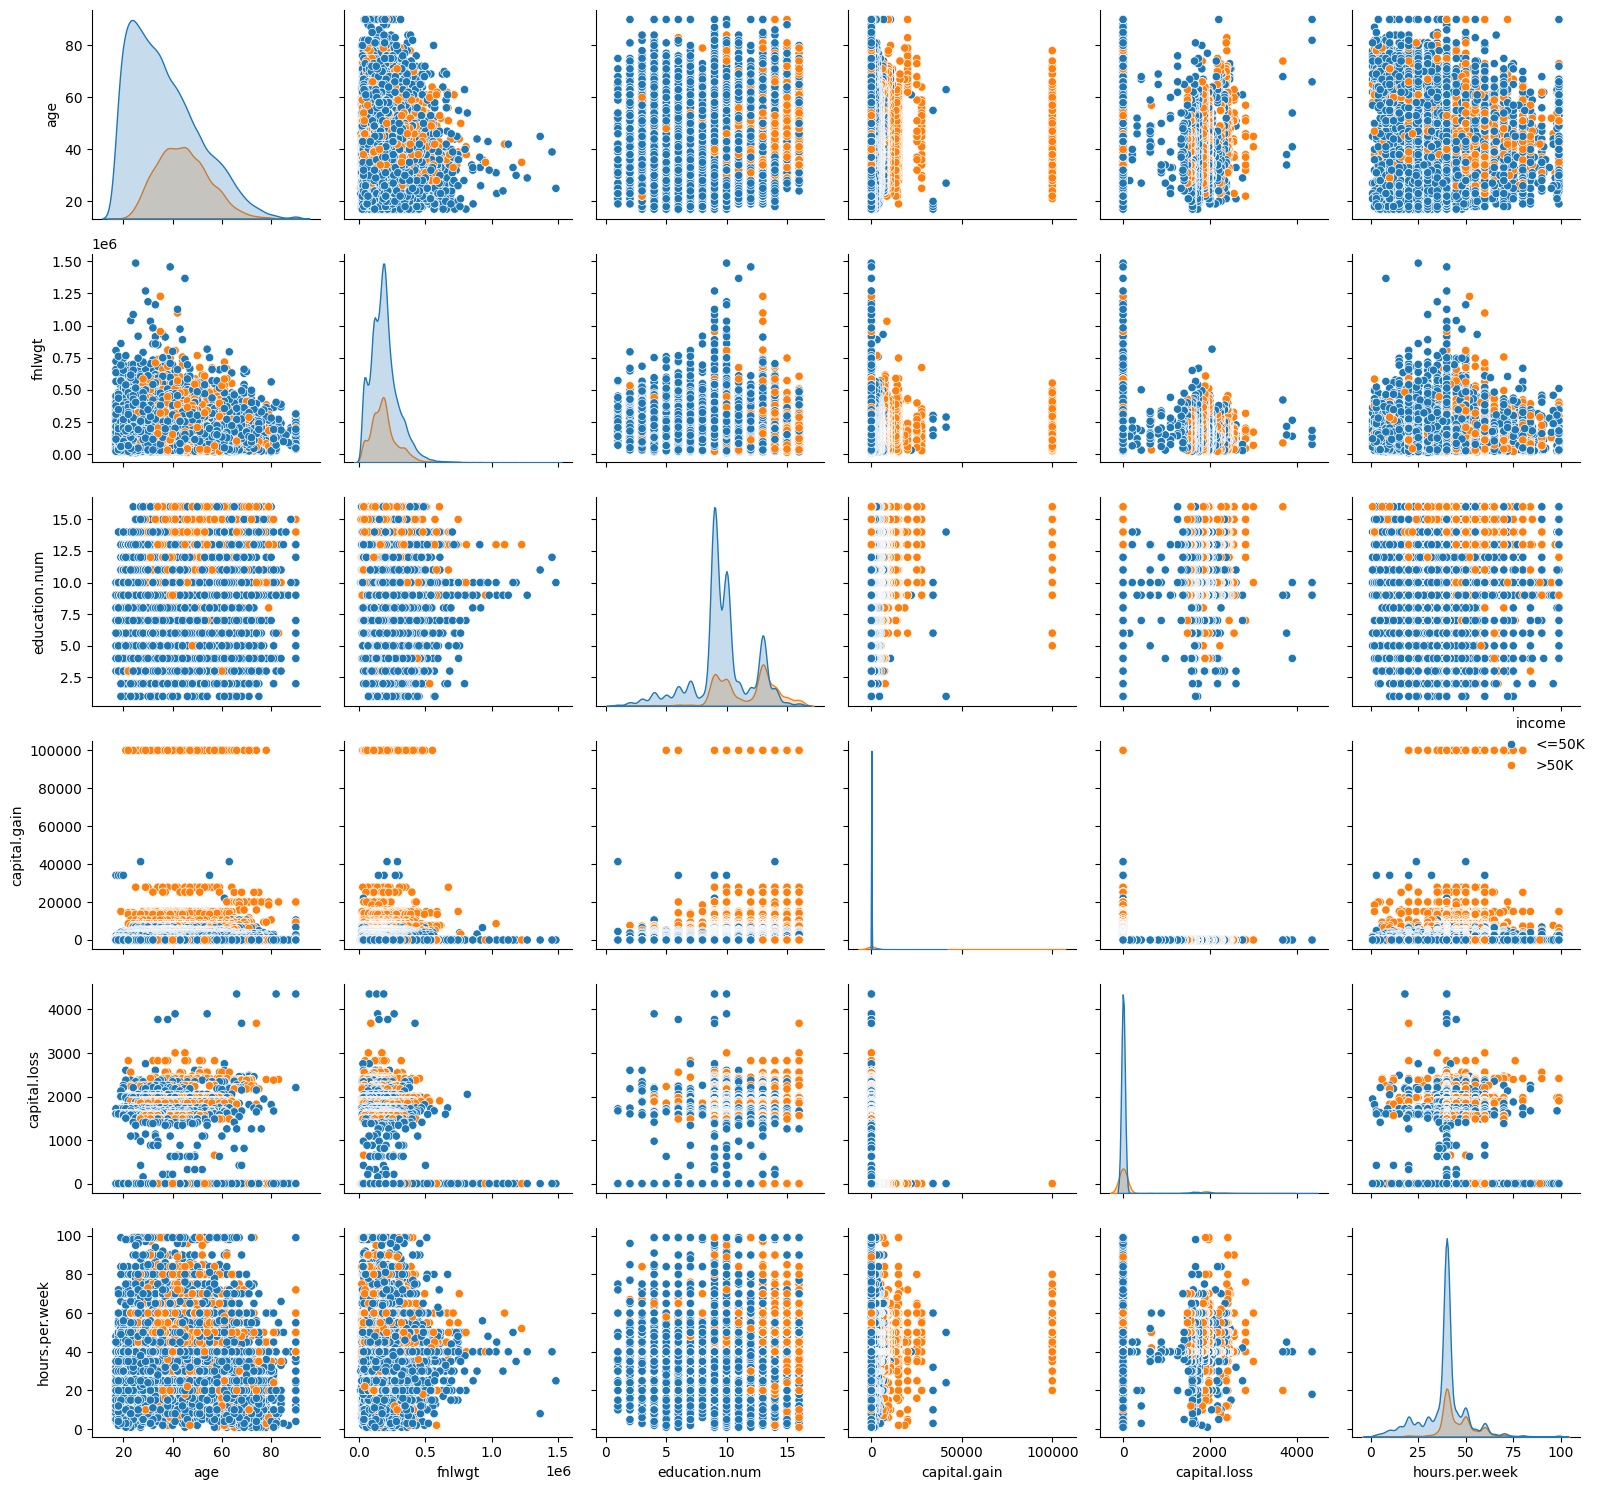

In [17]:
#Distribution of the table using a pairplot
plt.figure(figsize=(15,10))
sns.pairplot(data=table, diag_kind="kde", hue="income")
plt.tight_layout()
plt.show()

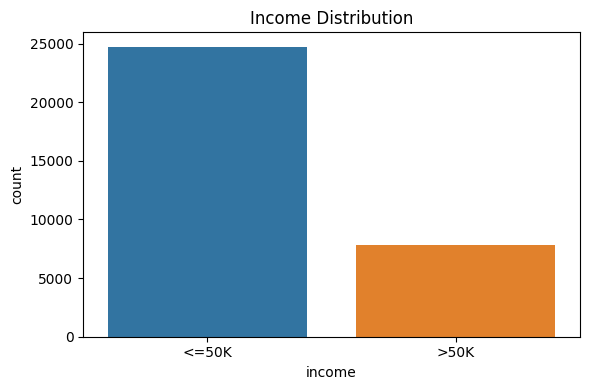

In [18]:
#Plotting the distribution of the target column
target_col = table["income"]
plt.figure(figsize=(6,4))
plt.title("Income Distribution")
sns.countplot(data=table, x=target_col, hue="income")
plt.tight_layout()
plt.show()

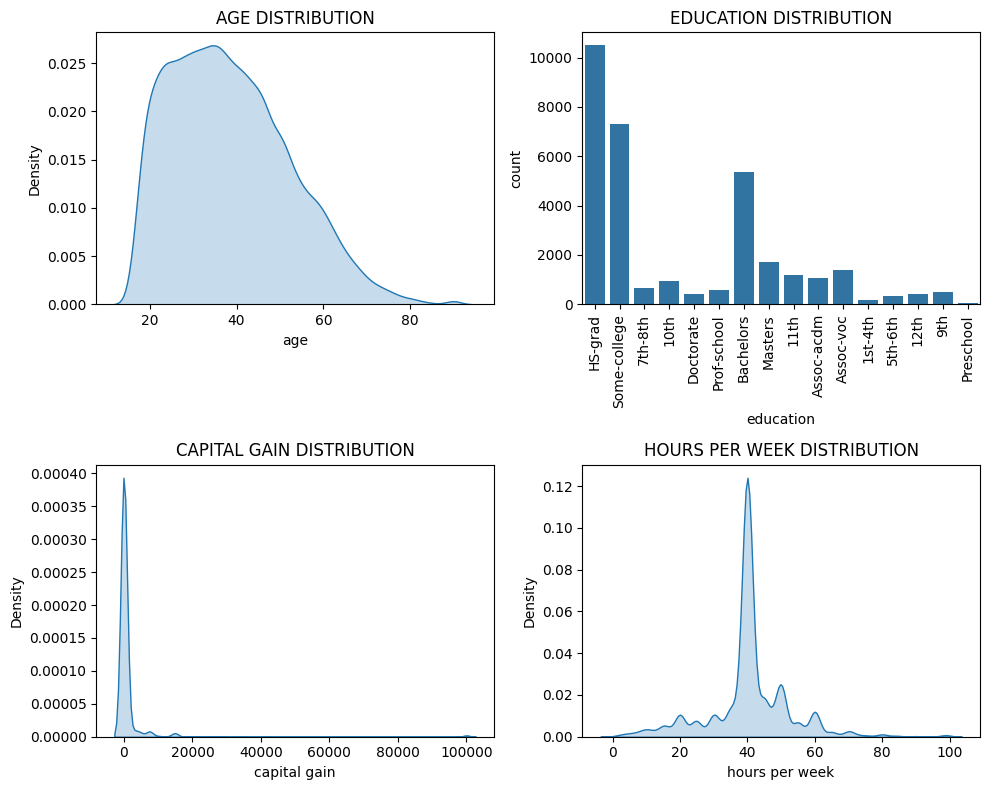

In [19]:
#Plotting the distribution of 3 to 5 features
feats = ["age","education", "capital.gain","hours.per.week"]
num_of_cols = 2
num_of_rows = math.ceil(len(feats)/num_of_cols)
fig, axes = plt.subplots(nrows=num_of_rows,ncols=num_of_cols, figsize=(10, 4*num_of_rows))
axes = axes.flatten()

#Plotting the plots
for ax, col in zip(axes, feats):
  if table[col].dtype == "object":
    sns.countplot(data=table, x=col, ax=ax)
    ax.tick_params(axis="x", rotation=90)
    ax.set_xlabel(f"{col.replace("."," ")}")
  else:
    sns.kdeplot(data=table, x=col, ax=ax, fill=True)
    ax.set_xlabel(f"{col.replace("."," ")}")

  ax.set_title(f"{col.replace("."," ").upper()} DISTRIBUTION")

#clearing remaining space
for ax in axes[len(feats):]:
  ax.set_visible(False)

plt.tight_layout()
plt.show()


##**Feature Engineeering and Encoding**

###**Age Group Feature**
Age is grouped into career-stage categories to capture workforce maturity and earning progression patterns. Individuals at different life stages often exhibit distinct income behavior, making grouped age potentially more informative for segmentation and predictive modeling than raw numerical age alone.

In [20]:
#Generating the Age group feature
table['age_group'] = pd.cut(
    table['age'],
    bins=[0, 25, 35, 50, 65, 100],
    labels=['Young Adult', 'Early Career', 'Mid Career', 'Pre-Retirement', 'Senior']
)

###**Financial Activity Feature**
This feature identifies individuals engaged in measurable investment or financial transactions. Financial activity often correlates with wealth accumulation and may improve prediction of high-income status.

In [21]:
#Creates the financial activity feature
table['financial_activity'] = (
    (table['capital.gain'] > 0) |
    (table['capital.loss'] > 0)
).astype(int)

### **Education Work Effort**

This feature combines education level and weekly working hours to represent an individual's productive workforce capacity.

From a business perspective, higher educational attainment combined with greater work commitment may indicate stronger earning potential, making this feature useful for income prediction.

In [22]:
#Creates the education work effort feature
table['education_work_effort'] = (
    table['education.num'] * table['hours.per.week']
)

### **Net Capital Feature**

This feature combines `capital gain` and `capital loss` to capture an individual's overall financial position.

It provides a clearer measure of net financial activity, which may reflect wealth accumulation patterns and improve income prediction. It helps distinguish between individuals with no financial activity and those with some level of investment.

In [23]:
#Creating the net capital feature
table['net_capital'] = table['capital.gain'] - table['capital.loss']

In [24]:
engr_feat_df = table[['age_group', 'financial_activity','education_work_effort', 'net_capital']]
engr_feat_df.sample(5)

,age_group,financial_activity,education_work_effort,net_capital
12421,Pre-Retirement,0,390,0
21324,Early Career,0,315,0
28308,Early Career,0,520,0
14394,Young Adult,0,520,0
4990,Mid Career,0,440,0


In [25]:
table.head(6)

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income,age_group,financial_activity,education_work_effort,net_capital
0,90,unknown,77053,HS-grad,9,Widowed,unknown,Not-in-family,White,Female,0,4356,40,United-States,<=50K,Senior,1,360,-4356
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K,Senior,1,162,-4356
2,66,unknown,186061,Some-college,10,Widowed,unknown,Unmarried,Black,Female,0,4356,40,United-States,<=50K,Senior,1,400,-4356
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K,Pre-Retirement,1,160,-3900
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K,Mid Career,1,400,-3900
5,34,Private,216864,HS-grad,9,Divorced,Other-service,Unmarried,White,Female,0,3770,45,United-States,<=50K,Early Career,1,405,-3770


In [26]:
table.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 19 columns):
 #   Column                 Non-Null Count  Dtype   
---  ------                 --------------  -----   
 0   age                    32561 non-null  int64   
 1   workclass              32561 non-null  object  
 2   fnlwgt                 32561 non-null  int64   
 3   education              32561 non-null  object  
 4   education.num          32561 non-null  int64   
 5   marital.status         32561 non-null  object  
 6   occupation             32561 non-null  object  
 7   relationship           32561 non-null  object  
 8   race                   32561 non-null  object  
 9   sex                    32561 non-null  object  
 10  capital.gain           32561 non-null  int64   
 11  capital.loss           32561 non-null  int64   
 12  hours.per.week         32561 non-null  int64   
 13  native.country         32561 non-null  object  
 14  income                 32561 non-null 

In [27]:
table.sample(10)

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income,age_group,financial_activity,education_work_effort,net_capital
3299,30,Private,110643,Masters,14,Married-civ-spouse,Adm-clerical,Husband,White,Male,4386,0,40,United-States,>50K,Early Career,1,560,4386
18687,33,State-gov,121245,Bachelors,13,Married-civ-spouse,Prof-specialty,Husband,White,Male,0,0,60,United-States,>50K,Early Career,0,780,0
27854,28,Private,102533,Some-college,10,Separated,Handlers-cleaners,Not-in-family,Black,Male,0,0,40,United-States,<=50K,Early Career,0,400,0
30043,34,Private,185556,Some-college,10,Never-married,Prof-specialty,Not-in-family,White,Female,0,0,12,United-States,>50K,Early Career,0,120,0
3669,36,Private,24106,HS-grad,9,Married-civ-spouse,Craft-repair,Husband,White,Male,3103,0,40,United-States,>50K,Mid Career,1,360,3103
6176,64,Local-gov,78866,HS-grad,9,Divorced,Adm-clerical,Not-in-family,White,Female,0,0,40,United-States,<=50K,Pre-Retirement,0,360,0
21251,52,Self-emp-not-inc,237868,Some-college,10,Never-married,Adm-clerical,Unmarried,White,Male,0,0,5,United-States,<=50K,Pre-Retirement,0,50,0
1177,53,Local-gov,137250,Masters,14,Widowed,Prof-specialty,Unmarried,Black,Female,0,1669,35,United-States,<=50K,Pre-Retirement,1,490,-1669
26355,52,Self-emp-not-inc,77336,Assoc-voc,11,Married-civ-spouse,Craft-repair,Husband,White,Male,0,0,40,United-States,<=50K,Pre-Retirement,0,440,0
18918,69,Private,312653,Some-college,10,Married-civ-spouse,Sales,Husband,White,Male,0,0,25,United-States,<=50K,Senior,0,250,0


###**Encoding Categorical Data**


#### **One Hot Encoding**
- These features are **non-ordinal**, meaning no category is greater or smaller than another.

- One-Hot Encoding prevents the model from assuming any hierarchical relationship between categories.

- We used the `drop_first=True` in one-Hot encoding so as to avoid multicollinearity or redundancy in the features it's applied to.


In [28]:
#Encoding the non ordinal categories with one hot encoding

nominal_cols = [
    'workclass',
    'occupation',
    'marital.status',
    'relationship',
    'race',
    'native.country',
    'sex',
    'income',
    'age_group',
]

encoded_df = pd.get_dummies(
    table,
    columns=nominal_cols,
    drop_first=True
)

encoded_df.head(5)

,age,fnlwgt,education,education.num,capital.gain,capital.loss,hours.per.week,financial_activity,education_work_effort,net_capital,...,native.country_United-States,native.country_Vietnam,native.country_Yugoslavia,native.country_unknown,sex_Male,income_>50K,age_group_Early Career,age_group_Mid Career,age_group_Pre-Retirement,age_group_Senior
0,90,77053,HS-grad,9,0,4356,40,1,360,-4356,...,True,False,False,False,False,False,False,False,False,True
1,82,132870,HS-grad,9,0,4356,18,1,162,-4356,...,True,False,False,False,False,False,False,False,False,True
2,66,186061,Some-college,10,0,4356,40,1,400,-4356,...,True,False,False,False,False,False,False,False,False,True
3,54,140359,7th-8th,4,0,3900,40,1,160,-3900,...,True,False,False,False,False,False,False,False,True,False
4,41,264663,Some-college,10,0,3900,40,1,400,-3900,...,True,False,False,False,False,False,False,True,False,False


In [29]:
encoded_df.select_dtypes(include="object").columns

Index(['education'], dtype='object')

We have to drop the `education` column because the `education.num` column indicates the education in numeric format.

In [30]:
encoded_df.drop(columns=["education"], inplace=True)

##**Preparing for Modeling**

In [31]:
#Selecting target and features
y = encoded_df["income_>50K"].astype(int)
X = encoded_df.drop(columns=["income_>50K"]).astype(float)

In [32]:
#Spliting and scaling data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### **Scaling Method Selection**

We used StandardScaler because the dataset contains numerical features with varying ranges, skewed distributions, and negative values.

In [33]:
print(X_train_scaled.std())
print(X_train_scaled.mean())

0.9945503681476412
-6.861909212587e-20


- The scaled training data produced a mean approximately equal to 0 and a standard deviation close to 1, confirming successful standardization.
- The deviation from exact 0 or 1 is due to floating point precision in computation

In [34]:
#Converting the scaled data back to a dataframe
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns)

In [35]:
X_test_scaled.head(5)

,age,fnlwgt,education.num,capital.gain,capital.loss,hours.per.week,financial_activity,education_work_effort,net_capital,workclass_Local-gov,...,native.country_Trinadad&Tobago,native.country_United-States,native.country_Vietnam,native.country_Yugoslavia,native.country_unknown,sex_Male,age_group_Early Career,age_group_Mid Career,age_group_Pre-Retirement,age_group_Senior
0,0.915161,0.060215,1.132528,1.709301,-0.217228,0.777316,2.574956,1.338727,1.715543,-0.263618,...,-0.024792,0.341785,-0.045458,-0.019875,-0.134333,0.704154,-0.600867,-0.721584,2.278920,-0.191713
1,0.694975,-1.547788,1.132528,-0.146857,-0.217228,-1.651056,-0.388356,-0.853070,-0.134831,-0.263618,...,-0.024792,0.341785,-0.045458,-0.019875,-0.134333,-1.420144,-0.600867,1.385840,-0.438804,-0.191713
2,1.942696,-0.674898,-0.417498,-0.146857,-0.217228,-0.841599,-0.388356,-0.796870,-0.134831,-0.263618,...,-0.024792,0.341785,-0.045458,-0.019875,-0.134333,0.704154,-0.600867,-0.721584,2.278920,-0.191713
3,-1.360093,-1.119349,-0.029991,-0.146857,-0.217228,-1.812948,-0.388356,-1.302670,-0.134831,-0.263618,...,-0.024792,0.341785,-0.045458,-0.019875,-0.134333,-1.420144,-0.600867,-0.721584,-0.438804,-0.191713
4,0.548185,-0.383007,-2.355030,-0.146857,-0.217228,0.372588,-0.388356,-1.302670,-0.134831,-0.263618,...,-0.024792,0.341785,-0.045458,-0.019875,-0.134333,0.704154,-0.600867,1.385840,-0.438804,-0.191713


##**Clustering Analysis**

In [36]:
#Running Kmeans from 2 to 10 and Silhoutte score
k_values = range(2, 11)
inertia_values = []
silhouette_scores = []

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10) #Initialize kmeans model
    cluster_labels = kmeans.fit_predict(X_train_scaled) #fit model and get labels

    inertia_value = kmeans.inertia_ #Get inertia value
    inertia_values.append(inertia_value)

    #handling silhoutte score
    score = silhouette_score(X_train_scaled, cluster_labels)
    silhouette_scores.append(score)

    print(f"K={k}: Inertia Value = {inertia_value:.4f}: Silhouette Score = {score:.4f}")

K=2: Inertia Value = 2010483.8213: Silhouette Score = 0.0560
K=3: Inertia Value = 1960878.6424: Silhouette Score = 0.0668
K=4: Inertia Value = 1933228.1224: Silhouette Score = 0.0558
K=5: Inertia Value = 1893454.4379: Silhouette Score = 0.0476
K=6: Inertia Value = 1859369.7397: Silhouette Score = 0.0515
K=7: Inertia Value = 1848955.0640: Silhouette Score = 0.0482
K=8: Inertia Value = 1816436.6027: Silhouette Score = 0.0505
K=9: Inertia Value = 1787827.1334: Silhouette Score = 0.0804
K=10: Inertia Value = 1760720.1439: Silhouette Score = 0.0778


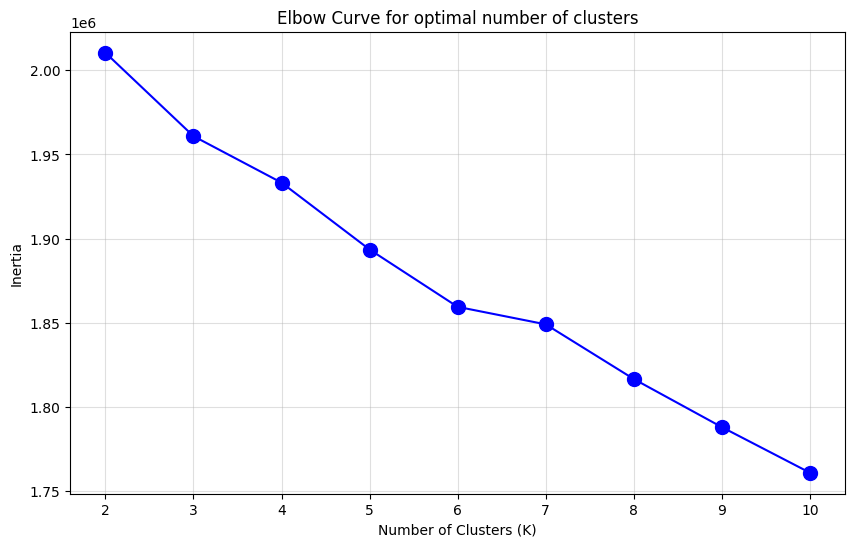

In [37]:
#Plotting the elbow curve
plt.figure(figsize=(10, 6))
plt.plot(k_values, inertia_values, marker='o', linestyle='-', color='b', markersize=10)
plt.title('Elbow Curve for optimal number of clusters')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.grid(True, alpha=0.4)
plt.show()

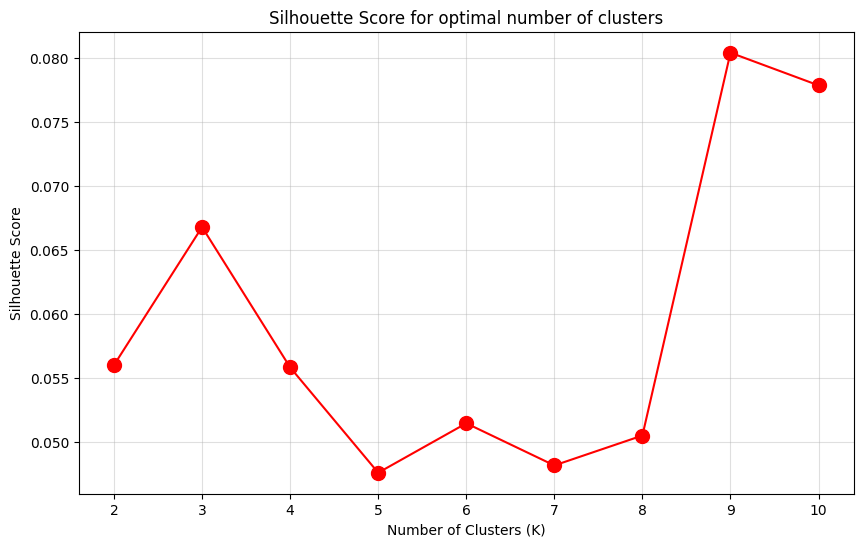

In [38]:
#Plotting the Silhoutte score
plt.figure(figsize=(10, 6))
plt.plot(k_values, silhouette_scores, marker='o', linestyle='-', color='r', markersize=10)
plt.title('Silhouette Score for optimal number of clusters')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.grid(True, alpha=0.4)
plt.show()

###**Final K Model**

In [39]:
#creating final kmeans model
final_kmeans = KMeans(n_clusters=9, random_state=42, n_init=10)
cluster_labels = final_kmeans.fit_predict(X_train_scaled) #Fitting & getting cluster labels

The elbow curve showed a gradual flattening rather than a sharply defined elbow.

K = 9 was selected because it achieved the highest silhouette score indicating the best relative balance between cluster cohesion and separation among the evaluated cluster sizes.


In [40]:
cluster_labels[:10]

array([5, 5, 5, 8, 1, 1, 8, 1, 5, 5], dtype=int32)

###**Profiling Each cluster**

In [41]:
#Add cluster labels to scaled dataframe
X_train_clustered = X_train_scaled.copy()
X_train_clustered['predicted_cluster'] = cluster_labels

X_test_clustered = X_test_scaled.copy()
X_test_clustered['predicted_cluster'] = final_kmeans.predict(X_test_scaled)  # predict X_test cluster


In [42]:
#Adding the cluster labels to the X_train portion of original dataset and calculating mean
df_train_original = table.loc[X_train.index].copy()
df_train_original['predicted_cluster'] = cluster_labels
cprofile = df_train_original.groupby("predicted_cluster").mean(numeric_only=True) #calculates numeric value means
round(cprofile, 2)

,age,fnlwgt,education.num,capital.gain,capital.loss,hours.per.week,financial_activity,education_work_effort,net_capital
predicted_cluster,,,,,,,,,
0,40.78,189097.50,9.17,418.43,44.32,32.02,0.09,292.11,374.11
1,42.72,187040.75,10.25,981.32,0.05,43.80,0.12,451.99,981.28
2,36.40,193012.30,10.47,518.92,0.34,41.40,0.07,435.93,518.58
3,46.57,195484.31,12.78,99999.00,0.00,49.61,1.00,644.44,99999.00
4,38.43,193938.45,10.53,550.89,124.93,42.39,0.14,449.67,425.97
5,25.18,196778.10,9.39,128.44,5.65,33.31,0.03,315.50,122.78
6,41.82,188092.37,11.05,0.00,1911.54,43.90,1.00,490.50,-1911.54
7,40.51,173947.14,10.92,2638.33,117.86,41.33,0.14,447.14,2520.47
8,42.95,187472.72,9.53,366.08,8.13,38.15,0.07,366.93,357.95


In [43]:
#Giving each cluster a name
cluster_names = {
    0: "Low Earners",
    1: "Upper-Mid Earners",
    2: "Skilled Mid Earners",
    3: "Top Earners",
    4: "Lower-Mid Earners",
    5: "Entry Earners",
    6: "Unstable High Earners",
    7: "Investment Driven Mid Earners",
    8: "Very Low Earners"
}

#Mapping cluster names to predicted clusters
df_train_original['cluster_name'] = df_train_original['predicted_cluster'].map(cluster_names)

df_train_original[["predicted_cluster", "cluster_name"]].value_counts().sort_index()


,,count
predicted_cluster,cluster_name,
0,Low Earners,1266
1,Upper-Mid Earners,9063
2,Skilled Mid Earners,4856
3,Top Earners,117
4,Lower-Mid Earners,398
5,Entry Earners,3461
6,Unstable High Earners,969
7,Investment Driven Mid Earners,51
8,Very Low Earners,2611


###**Visualizing the clusters in 2D using PCA**

In [44]:
pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train_scaled)

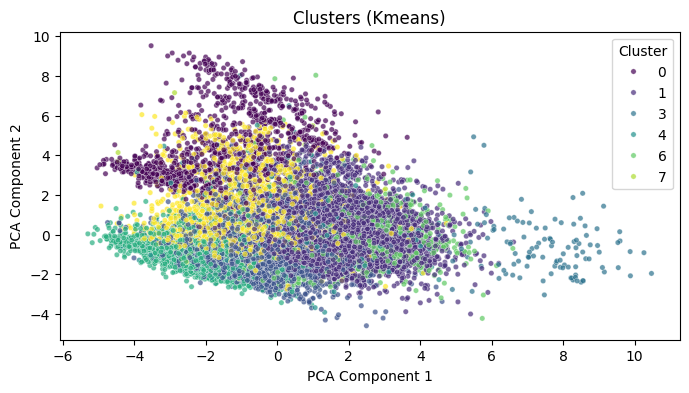

In [45]:
#Plotting PCA clusters
plt.figure(figsize=(8, 4))
sns.scatterplot(x=X_train_pca[:, 0], y=X_train_pca[:, 1], hue=cluster_labels, palette='viridis', alpha=0.7, s=15)
plt.title("Clusters (Kmeans)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.legend(title="Cluster")
plt.show()

##**Classification**

###**Model Selection**

We will be working with three classifier models for this project namely `LogisticRegression`, `DecisionTree` and `RandomForest`, this will provide a linear to non-linear to ensemble approach to the problem.

####**1. Logistic Regression**

`LogisticRegression` is being used as the first classification model because:

- It provides a strong base for comparison with more complex models
- It models the relationship between features and the log-odds of the target
- It is highly interpretable and easy to explain

In [46]:
#Using Logistic Regression Model
logr_model = LogisticRegression(random_state=42, max_iter=1000) #Initializing model
logr_model.fit(X_train_scaled, y_train) #Training model
y_pred_logr = logr_model.predict(X_test_scaled) #Predicting the outcome
y_prob_logr = logr_model.predict_proba(X_test_scaled)[:,1] #Predicting the probability

In [47]:
#Model Evaluation
logr_accuracy = accuracy_score(y_test,y_pred_logr)
logr_precision = precision_score(y_test, y_pred_logr)
logr_recall = recall_score(y_test, y_pred_logr)
logr_f1 = f1_score(y_test,y_pred_logr)
logr_roc_auc = roc_auc_score(y_test, y_prob_logr)

print("LOGISTICS REGRESSION PERFORMANCE\n")
print(f"Accuracy: {logr_accuracy:.4f}")
print(f"Precision: {logr_precision:.4f}")
print(f"Recall: {logr_recall:.4f}")
print(f"F1 Score: {logr_f1:.4f}")
print(f"ROC AUC Score: {logr_roc_auc:.4}")

LOGISTICS REGRESSION PERFORMANCE

Accuracy: 0.8532
Precision: 0.7314
Recall: 0.6169
F1 Score: 0.6693
ROC AUC Score: 0.9065


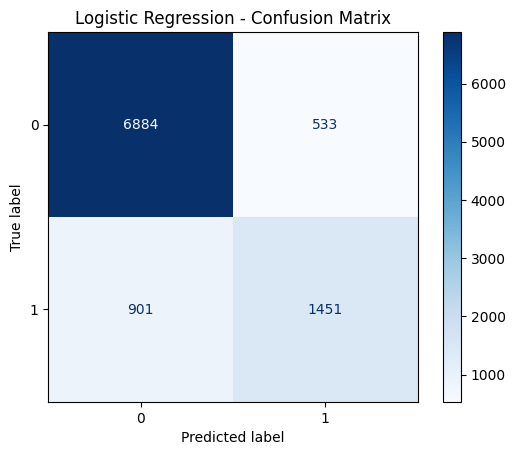

In [48]:
# Confusion Matrix
logr_cm = confusion_matrix(y_test, y_pred_logr)
logr_disp = ConfusionMatrixDisplay(confusion_matrix=logr_cm, display_labels=logr_model.classes_)
logr_disp.plot(cmap=plt.cm.Blues)
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

####**2. Decision Tree Classifier**

`DecisionTreeClassifier` is used because it handles non-linear relationships in a dataset.

- It handles both numerical and categorical features effectively
- It captures non-linear patterns and feature interactions automatically
- It is highly interpretable through tree visualization

In [49]:
#Using Decision Tree Classifier
dtree = DecisionTreeClassifier(random_state=42, min_samples_split=20, min_samples_leaf=10, max_depth=10)
dtree.fit(X_train_scaled, y_train)
y_pred_dtree = dtree.predict(X_test_scaled)
y_prob_dtree = dtree.predict_proba(X_test_scaled)[:,1]

In [50]:
#Evaluating the model
dtree_accuracy = accuracy_score(y_test, y_pred_dtree)
dtree_precision = precision_score(y_test, y_pred_dtree)
dtree_recall = recall_score(y_test, y_pred_dtree)
dtree_f1 = f1_score(y_test, y_pred_dtree)
dtree_roc_auc = roc_auc_score(y_test, y_prob_dtree)

print("DECISION TREE PERFORMANCE\n")
print(f"Accuracy: {dtree_accuracy:.4f}")
print(f"Precision: {dtree_precision:.4f}")
print(f"Recall: {dtree_recall:.4f}")
print(f"F1 Score: {dtree_f1:.4f}")
print(f"ROC AUC Score: {dtree_roc_auc:.4f}")

DECISION TREE PERFORMANCE

Accuracy: 0.8529
Precision: 0.7180
Recall: 0.6407
F1 Score: 0.6772
ROC AUC Score: 0.8980


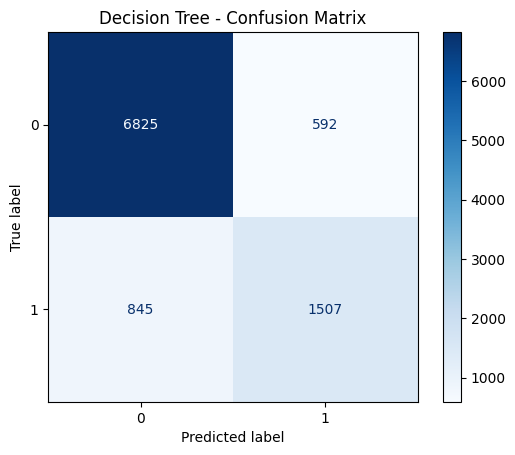

In [51]:
#Confusion Matrix
dtree_cm = confusion_matrix(y_test, y_pred_dtree)
dtree_disp = ConfusionMatrixDisplay(confusion_matrix=dtree_cm, display_labels=dtree.classes_)
dtree_disp.plot(cmap=plt.cm.Blues)
plt.title("Decision Tree - Confusion Matrix")
plt.show()

In [52]:
dtree_importance = pd.DataFrame({
    "feature": X_train_scaled.columns,
    "importance": dtree.feature_importances_
}).sort_values("importance", ascending=False).head(10)

dtree_importance

,feature,importance
32,marital.status_Married-civ-spouse,0.393095
2,education.num,0.176259
8,net_capital,0.114265
3,capital.gain,0.082781
7,education_work_effort,0.073754
4,capital.loss,0.051203
0,age,0.046879
19,occupation_Exec-managerial,0.013421
1,fnlwgt,0.011555
25,occupation_Prof-specialty,0.005017


#### **3. Random Forest Classifier**

`RandomForestClassfier` is being used to improve performance and captures complex non-linear relationships effectively.

- It reduces overfitting by combining multiple decision trees
- It improves generalization performance on unseen data

In [53]:
#Using Random Forest Classifier
rforest_model = RandomForestClassifier(random_state=42,max_depth=10, min_samples_split=20, min_samples_leaf=10, n_estimators=100)
rforest_model.fit(X_train_scaled, y_train)
y_pred_rforest = rforest_model.predict(X_test_scaled)
y_prob_rforest = rforest_model.predict_proba(X_test_scaled)[:,1]

In [54]:
#Evaluating random forest model
rforest_accuracy = accuracy_score(y_test, y_pred_rforest)
rforest_precision = precision_score(y_test, y_pred_rforest)
rforest_recall = recall_score(y_test, y_pred_rforest)
rforest_f1 = f1_score(y_test, y_pred_rforest)
rforest_roc_auc = roc_auc_score(y_test, y_prob_rforest)

print("RANDOM FOREST PERFORMANCE\n")
print(f"Accuracy: {rforest_accuracy:.4f}")
print(f"Precision: {rforest_precision:.4f}")
print(f"Recall: {rforest_recall:.4f}")
print(f"F1 Score: {rforest_f1:.4f}")
print(f"ROC AUC Score: {rforest_roc_auc:.4f}")

RANDOM FOREST PERFORMANCE

Accuracy: 0.8554
Precision: 0.7989
Recall: 0.5336
F1 Score: 0.6398
ROC AUC Score: 0.9086


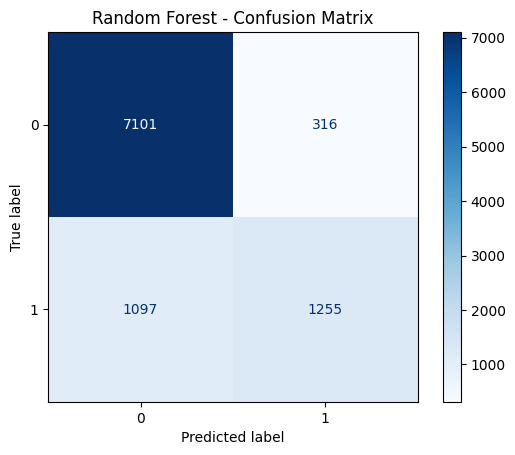

In [55]:
#Random Forest Confusion Matrix
rforest_cm = confusion_matrix(y_test, y_pred_rforest)
rforest_disp = ConfusionMatrixDisplay(confusion_matrix=rforest_cm, display_labels=rforest_model.classes_)
rforest_disp.plot(cmap=plt.cm.Blues)
plt.title("Random Forest - Confusion Matrix")
plt.show()

In [56]:
rforest_importance = pd.DataFrame({
    "feature": X_train_scaled.columns,
    "importance": rforest_model.feature_importances_
}).sort_values("importance", ascending=False).head(10)

rforest_importance

,feature,importance
32,marital.status_Married-civ-spouse,0.180919
8,net_capital,0.125433
3,capital.gain,0.097065
7,education_work_effort,0.096682
2,education.num,0.084449
34,marital.status_Never-married,0.055044
0,age,0.054805
6,financial_activity,0.042447
19,occupation_Exec-managerial,0.030907
5,hours.per.week,0.027707


In [57]:
#Comparison Table
print("MODEL COMPARISON TABLE\n")
model_performance = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree", "Random Forest"],
    "Accuracy": [logr_accuracy, dtree_accuracy, rforest_accuracy],
    "Precision": [logr_precision, dtree_precision, rforest_precision],
    "Recall": [logr_recall, dtree_recall, rforest_recall],
    "F1 Score": [logr_f1, dtree_f1, rforest_f1],
    "ROC AUC Score": [logr_roc_auc, dtree_roc_auc, rforest_roc_auc]
})

model_performance

MODEL COMPARISON TABLE



,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC Score
0,Logistic Regression,0.853209,0.731351,0.616922,0.669280,0.906515
1,Decision Tree,0.852902,0.717961,0.640731,0.677151,0.898017
2,Random Forest,0.855359,0.798854,0.533588,0.639816,0.908647


**Note:** Although tree-based models like Decision Tree and Random Forest do not require feature scaling, the standardized dataset was used across all models to maintain consistency in preprocessing and ensure fair comparison during evaluation.

##**Imbalance Handling**

###**Checking for Imbalance**

In [58]:
#Checking the imbalance on the y_train
y_train.value_counts(normalize=True).round(3)

,proportion
income_>50K,
0,0.759
1,0.241


In [59]:
#Checking the imbalance on the y_test
y_test.value_counts(normalize=True).round(3)

,proportion
income_>50K,
0,0.759
1,0.241


The ratio of >50k is at 24% across both y_train and y_test.
- This means that only about 24% earns income higher than 50k while the other 76% earns lesser.  
- The cost of this is that the model misses actual earners earning above 50k which is what the business wants to find.

###**Using Class weight for Imbalance handling**

####**For Logistic Regression**

In [60]:
#Using Logistic Regression Model
logr_balanced = LogisticRegression(random_state=42, max_iter=1000, class_weight="balanced" ) #Initializing model
logr_balanced.fit(X_train_scaled, y_train) #Training model
y_pred_logr_bal = logr_balanced.predict(X_test_scaled) #Predicting the outcome
y_prob_logr_bal = logr_balanced.predict_proba(X_test_scaled)[:,1] #Predicting the probability

print(classification_report(y_test, y_pred_logr_bal))

              precision    recall  f1-score   support

           0       0.94      0.80      0.87      7417
           1       0.57      0.84      0.68      2352

    accuracy                           0.81      9769
   macro avg       0.76      0.82      0.77      9769
weighted avg       0.85      0.81      0.82      9769



####**For Decision Tree**

In [61]:
#Using Decision Tree Classifier
dtree_balanced = DecisionTreeClassifier(random_state=42, min_samples_split=20, min_samples_leaf=5, max_depth=20, class_weight="balanced")
dtree_balanced.fit(X_train_scaled, y_train)
y_pred_dtree_bal = dtree_balanced.predict(X_test_scaled)
y_prob_dtree_bal = dtree_balanced.predict_proba(X_test_scaled)[:,1]

print(classification_report(y_test, y_pred_dtree_bal))

              precision    recall  f1-score   support

           0       0.93      0.79      0.85      7417
           1       0.55      0.82      0.66      2352

    accuracy                           0.80      9769
   macro avg       0.74      0.80      0.76      9769
weighted avg       0.84      0.80      0.81      9769



####**For random Forest**

In [62]:
rforest_balanced = RandomForestClassifier(random_state=42,max_depth=20, min_samples_split=20, min_samples_leaf=5, n_estimators=200, class_weight="balanced")
rforest_balanced.fit(X_train_scaled, y_train)

y_pred_rforest_bal = rforest_balanced.predict(X_test_scaled)
y_prob_rforest_bal = rforest_balanced.predict_proba(X_test_scaled)[:,1]

classification_report_str = classification_report(y_test, y_pred_rforest_bal)
print(classification_report_str)


              precision    recall  f1-score   support

           0       0.94      0.82      0.87      7417
           1       0.59      0.84      0.70      2352

    accuracy                           0.82      9769
   macro avg       0.77      0.83      0.79      9769
weighted avg       0.86      0.82      0.83      9769



###**Using Threshold Tuning for Imbalance Handling**

####**For Logistic Regression**

In [63]:
logr_thresholds = [0.5, 0.4, 0.3, 0.2]
logr_threshold_results = []

for t in logr_thresholds:
    y_pred_t = (y_prob_logr >= t).astype(int)

    logr_threshold_results.append({
        "Threshold": t,
        "Accuracy": accuracy_score(y_test, y_pred_t),
        "Precision": precision_score(y_test, y_pred_t),
        "Recall": recall_score(y_test, y_pred_t),
        "F1 Score": f1_score(y_test, y_pred_t),
        "ROC AUC Score": roc_auc_score(y_test, y_prob_logr)
    })


pd.DataFrame(logr_threshold_results).round(3)



,Threshold,Accuracy,Precision,Recall,F1 Score,ROC AUC Score
0,0.5,0.853,0.731,0.617,0.669,0.907
1,0.4,0.849,0.681,0.704,0.692,0.907
2,0.3,0.830,0.613,0.796,0.693,0.907
3,0.2,0.792,0.542,0.878,0.670,0.907


####**For Decision Tree**

In [64]:
dtree_thresholds = [0.5, 0.4, 0.3, 0.2]
dtree_threshold_results = []

for t in dtree_thresholds:
    y_pred_t = (y_prob_dtree >= t).astype(int)

    dtree_threshold_results.append({
        "Threshold": t,
        "Accuracy": accuracy_score(y_test, y_pred_t),
        "Precision": precision_score(y_test, y_pred_t),
        "Recall": recall_score(y_test, y_pred_t),
        "F1 Score": f1_score(y_test, y_pred_t),
        "ROC AUC Score": roc_auc_score(y_test, y_prob_dtree)
    })


pd.DataFrame(dtree_threshold_results).round(3)



,Threshold,Accuracy,Precision,Recall,F1 Score,ROC AUC Score
0,0.5,0.853,0.717,0.641,0.677,0.898
1,0.4,0.851,0.707,0.651,0.677,0.898
2,0.3,0.824,0.600,0.803,0.687,0.898
3,0.2,0.786,0.533,0.875,0.663,0.898


####**For Random Forest**

In [65]:
thresholds = [0.5, 0.4, 0.3, 0.2]
threshold_results = []

for t in thresholds:
    y_pred_t = (y_prob_rforest >= t).astype(int)

    threshold_results.append({
        "Threshold": t,
        "Accuracy": accuracy_score(y_test, y_pred_t),
        "Precision": precision_score(y_test, y_pred_t),
        "Recall": recall_score(y_test, y_pred_t),
        "F1 Score": f1_score(y_test, y_pred_t),
        "ROC AUC Score": roc_auc_score(y_test, y_prob_rforest)
    })


pd.DataFrame(threshold_results).round(3)



,Threshold,Accuracy,Precision,Recall,F1 Score,ROC AUC Score
0,0.5,0.855,0.799,0.534,0.640,0.909
1,0.4,0.851,0.710,0.648,0.677,0.909
2,0.3,0.822,0.594,0.817,0.688,0.909
3,0.2,0.746,0.485,0.923,0.636,0.909


####**Precision-Recall Curve**

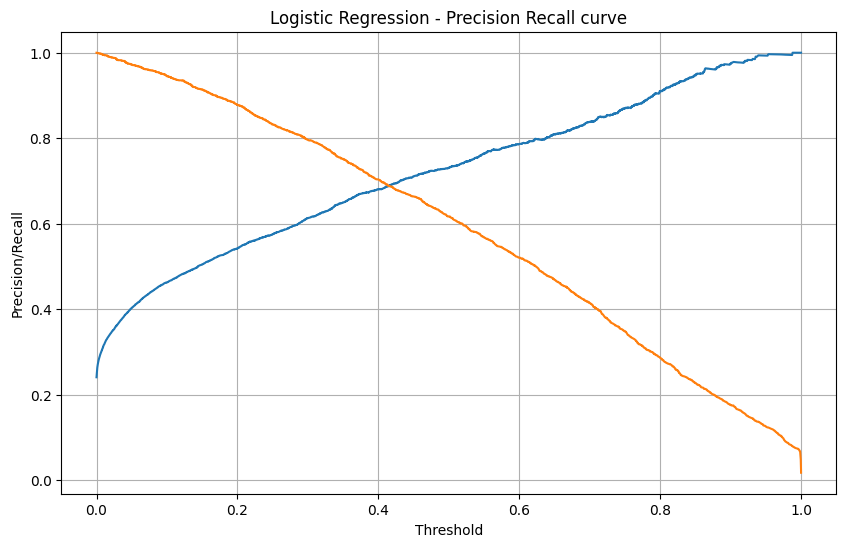

In [66]:
#For Logistic Regression
plt.figure(figsize=(10, 6))
prec, rec, thr = precision_recall_curve(y_test, y_prob_logr)
plt.plot(thr, prec[:-1], label='Precision')
plt.plot(thr, rec[:-1], label='Recall')
plt.xlabel('Threshold')
plt.ylabel('Precision/Recall')
plt.title("Logistic Regression - Precision Recall curve")
plt.grid(True)
plt.show()

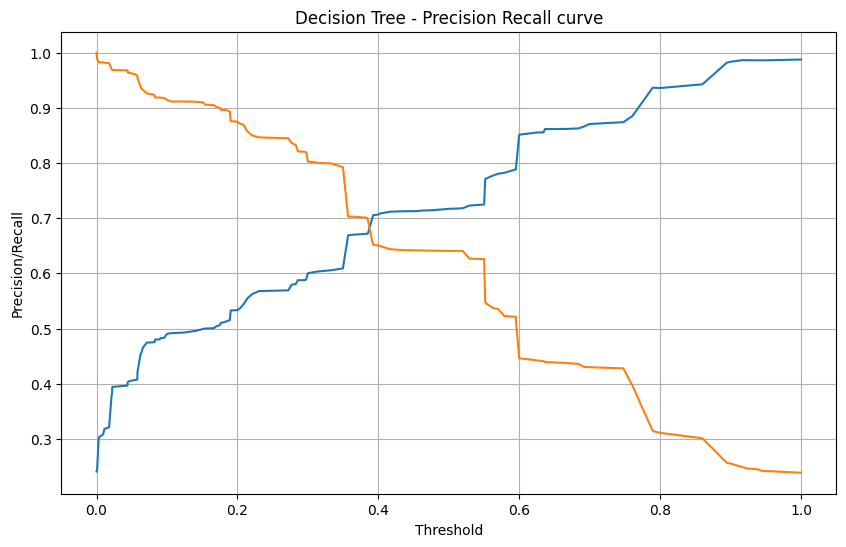

In [67]:
#For Decision tree
plt.figure(figsize=(10, 6))
prec, rec, thr = precision_recall_curve(y_test, y_prob_dtree)
plt.plot(thr, prec[:-1], label='Precision')
plt.plot(thr, rec[:-1], label='Recall')
plt.xlabel('Threshold')
plt.ylabel('Precision/Recall')
plt.title("Decision Tree - Precision Recall curve")
plt.grid(True)
plt.show()

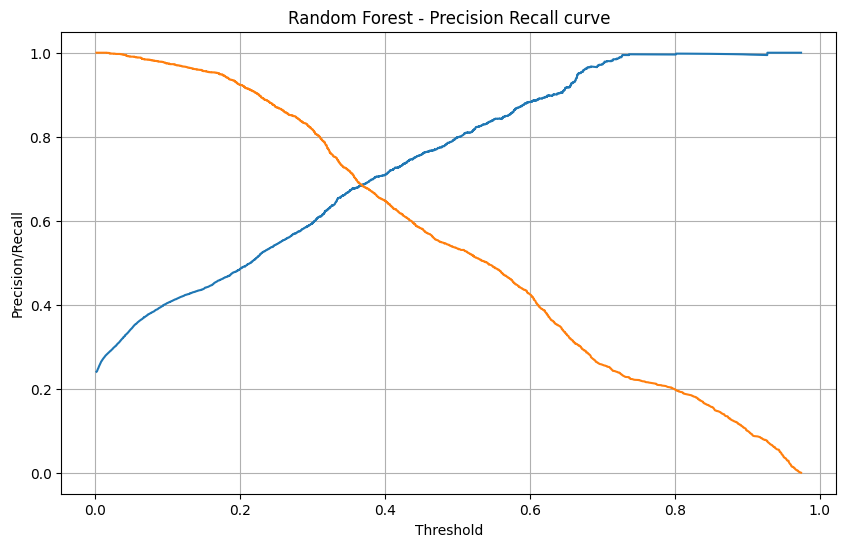

In [68]:
#For random forest
plt.figure(figsize=(10, 6))
prec, rec, thr = precision_recall_curve(y_test, y_prob_rforest)
plt.plot(thr, prec[:-1], label='Precision')
plt.plot(thr, rec[:-1], label='Recall')
plt.xlabel('Threshold')
plt.ylabel('Precision/Recall')
plt.title("Random Forest - Precision Recall curve")
plt.grid(True)
plt.show()

###**Using SMOTE**

In [69]:
!pip install imbalanced-learn -q

In [70]:
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)

In [71]:
y_train_smote.value_counts()

,count
income_>50K,
0,17303
1,17303


####**For Logistic Regression**

In [72]:
#Using Logistic Regression Model
logr_smote = LogisticRegression(random_state=42, max_iter=1000) #Initializing model
logr_smote.fit(X_train_smote, y_train_smote) #Training model
y_pred_logr_smote = logr_smote.predict(X_test_scaled) #Predicting the outcome
y_prob_logr_smote = logr_smote.predict_proba(X_test_scaled)[:,1] #Predicting the probability

print(classification_report(y_test, y_pred_logr_smote))

              precision    recall  f1-score   support

           0       0.94      0.81      0.87      7417
           1       0.58      0.84      0.68      2352

    accuracy                           0.81      9769
   macro avg       0.76      0.82      0.78      9769
weighted avg       0.85      0.81      0.82      9769



####**For Decision Tree**

In [73]:
#Using Decision Tree Classifier
dtree_smote = DecisionTreeClassifier(random_state=42, min_samples_split=20, min_samples_leaf=20, max_depth=10)
dtree_smote.fit(X_train_scaled, y_train)
y_pred_dtree_smote = dtree_balanced.predict(X_test_scaled)
y_prob_dtree_smote = dtree_balanced.predict_proba(X_test_scaled)[:,1]

print(classification_report(y_test, y_pred_dtree_bal))

              precision    recall  f1-score   support

           0       0.93      0.79      0.85      7417
           1       0.55      0.82      0.66      2352

    accuracy                           0.80      9769
   macro avg       0.74      0.80      0.76      9769
weighted avg       0.84      0.80      0.81      9769



####**For Random Forest**

In [74]:
rforest_smote = RandomForestClassifier(
    n_estimators=200,
    max_depth=20,
    min_samples_split=20,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)
rforest_smote.fit(X_train_smote, y_train_smote)
y_pred_rforest_smote = rforest_smote.predict(X_test_scaled)
y_prob_rforest_smote = rforest_smote.predict_proba(X_test_scaled)[:, 1]

print(classification_report(y_test, y_pred_rforest_smote))

              precision    recall  f1-score   support

           0       0.93      0.84      0.88      7417
           1       0.60      0.79      0.68      2352

    accuracy                           0.82      9769
   macro avg       0.76      0.81      0.78      9769
weighted avg       0.85      0.82      0.83      9769



###**Comparision Table for the Imbalance handler**

In [75]:
def evaluate_model(model_name, y_true, y_pred, y_prob):
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1 Score": f1_score(y_true, y_pred),
        "ROC AUC Score": roc_auc_score(y_true, y_prob)
    }

Because missing a true high earner costs more than a wasted contact, we
accept lower precision in exchange for higher recall. This shifts the optimal
threshold below the default 0.5.

At threshold = 0.3, recall rises significantly while precision drops
moderately which means we catch more actual high earners at the cost of some
false positives.

In [76]:
y_pred_threshold_logr = (y_prob_logr >= 0.3).astype(int)
y_pred_threshold_dtree = (y_prob_dtree >= 0.3).astype(int)
y_pred_threshold_rf = (y_prob_rforest >= 0.3).astype(int)



imbalance_results = pd.DataFrame([
    evaluate_model("Baseline LRegression", y_test, y_pred_logr, y_prob_logr),
    evaluate_model("LRegression + class_weight", y_test, y_pred_logr_bal, y_prob_logr_bal),
    evaluate_model("LRegression + threshold 0.3", y_test, y_pred_threshold_logr, y_prob_logr),
    evaluate_model("LRegression + SMOTE", y_test, y_pred_logr_smote, y_prob_logr_smote),
    evaluate_model("Baseline DTree", y_test, y_pred_dtree, y_prob_dtree),
    evaluate_model("DTree + class_weight", y_test, y_pred_dtree_bal, y_prob_dtree_bal),
    evaluate_model("Dtree + threshold 0.3", y_test, y_pred_threshold_dtree, y_prob_dtree),
    evaluate_model("Dtree + SMOTE", y_test, y_pred_dtree_smote, y_prob_dtree_smote),
    evaluate_model("Baseline RForest", y_test, y_pred_rforest, y_prob_rforest),
    evaluate_model("RForest + class_weight", y_test, y_pred_rforest_bal, y_prob_rforest_bal),
    evaluate_model("RForest + threshold 0.3", y_test, y_pred_threshold_rf, y_prob_rforest),
    evaluate_model("RForest + SMOTE", y_test, y_pred_rforest_smote, y_prob_rforest_smote),

])

imbalance_results.round(2).sort_values('F1 Score', ascending=False)

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC Score
9,RForest + class_weight,0.82,0.59,0.84,0.70,0.91
2,LRegression + threshold 0.3,0.83,0.61,0.80,0.69,0.91
6,Dtree + threshold 0.3,0.82,0.60,0.80,0.69,0.90
10,RForest + threshold 0.3,0.82,0.59,0.82,0.69,0.91
11,RForest + SMOTE,0.82,0.60,0.79,0.68,0.91
3,LRegression + SMOTE,0.81,0.58,0.84,0.68,0.91
1,LRegression + class_weight,0.81,0.57,0.84,0.68,0.91
4,Baseline DTree,0.85,0.72,0.64,0.68,0.90
0,Baseline LRegression,0.85,0.73,0.62,0.67,0.91
5,DTree + class_weight,0.80,0.55,0.82,0.66,0.87


##**The Tie In**

###**Rate of Positive Class**

In [77]:
eval_df = pd.DataFrame(X_train_clustered).copy()
eval_df["cluster"] = cluster_labels
eval_df["income"] = y_train.values

cluster_rates = eval_df.groupby("cluster")["income"].mean()

cluster_rates.sort_values(ascending=False)


,income
cluster,
3,1.000000
6,0.532508
1,0.435397
4,0.233668
7,0.176471
0,0.103476
2,0.103171
8,0.056683
5,0.008090


###**Observation**
The clustering reveals that capital activity drives income
separation. Clusters 3, 6 and 7 contributes strongly to the label prediction.

- Cluster 3 stood out as a very strong predictor of high income, since everyone in that group earned above 50K.

- Cluster 1 and Cluster 7 also showed a moderate relationship with higher income, meaning people in those groups were more likely to earn above 50K compared to others.

- Cluster 6 show an unstable capital movement indicating losses in investment activities.

- On the other hand, clusters like 0, 2, 8, and 5 were mostly made up of moderate to low-income earners but not much variation within them.

Overall, this tells us that the data naturally separates people into clear income groups based on their financial activity, capital gain and losses.

##**Conclusion & Recommendation**

### **1. Which model would you deploy and why?**

**Random Forest Classifier (Class Weight):**  Although the Logistic Regression and Decision Tree models performed well, the Random Forest achieved the best overall performance with the highest F1 Score and high Recall score which is better for this business problem. It was also better at capturing complex and non-linear relationships in the dataset.

---

### **2. What would you do differently if you had another month?**

If we had another month, we would focus on improving both the modeling process and the business interpretation of the results.

We would improve the following:

- Performing more advanced hyperparameter tuning using GridSearchCV or RandomizedSearchCV.

- Testing additional models such as XGBoost etc.

- Engineering more meaningful features from occupation, education, and financial variables.


These improvements could increase model performance, interpretability, and practical business value.


---

### 3. What did your clusters reveal that the classifier missed?

The clustering analysis revealed hidden patterns and income-related groups that the classifier alone could not fully explain.

While the classifier focused on predicting whether someone earns above or below \$50K, clustering helped uncover different types of earners within the dataset.

**For example:**
- Some groups had high education levels and long working hours but only moderate income.
- Another cluster showed people with strong investment activity but unstable income patterns.
- Certain clusters represented very low earners with limited education and fewer working hours.
- The clustering also highlighted lifestyle and workforce behavior differences that were not obvious from classification metrics alone.

Overall, clustering provided a deeper understanding of population segments and behavioral patterns, which can help businesses make more targeted decisions.

---

### 4. What was the hardest decision your team made and why?
One of the hardest decisions our team made was selecting the final number of clusters for the K-Means model.

The elbow curve did not show a very clear turning point, which made it difficult to determine the optimal value of K. After comparing the silhouette scores and reviewing the cluster separation, we decided to use `9 clusters` because it produced the best balance between cluster cohesion and separation.

This decision was challenging because choosing too few clusters would oversimplify the data, while too many clusters could create groups were there might be similar or identical datapoints in a group. We had to consider the business need which greatly reflected on the cluster naming.

## **Data Dictionary**

| Column Name              | Data Type | Description                                                                 | Example Value            |
|---------------------------|-----------|-----------------------------------------------------------------------------|--------------------------|
| age                       | Integer   | Age of the individual in years                                             | 69                       |
| workclass                 | Categorical | Employment type or work sector of the individual                         | Private                  |
| fnlwgt                    | Integer   | Final sampling weight assigned by the census                              | 104003                   |
| education                 | Categorical | Highest education level attained                                          | HS-grad                  |
| education.num             | Integer   | Numerical representation of education level                               | 9                        |
| marital.status            | Categorical | Marital status of the individual                                          | Married-civ-spouse       |
| occupation                | Categorical | Type of job or profession                                                 | Sales                    |
| relationship              | Categorical | Relationship status within the household                                  | Husband                  |
| race                      | Categorical | Race category of the individual                                           | White                    |
| sex                       | Categorical | Gender of the individual                                                  | Male                     |
| capital.gain              | Integer   | Income earned from capital investments                                    | 3674                     |
| capital.loss              | Integer   | Loss incurred from capital investments                                    | 0                        |
| hours.per.week            | Integer   | Number of working hours per week                                          | 40                       |
| native.country            | Categorical | Country of origin of the individual                                      | United-States            |
| income                    | Categorical | Income class label (target variable)                                      | >50K                     |
| age_group                 | Categorical | Engineered feature grouping individuals by life/career stage             | Mid Career               |
| financial_activity        | Binary (0/1) | Indicates whether the individual has capital gain/loss activity         | 1                        |
| education_work_effort     | Integer   | Engineered feature: education.num × hours.per.week                        | 378                      |
| net_capital               | Integer   | Engineered feature: capital.gain − capital.loss                           | 3674                     |

**Note:** fnlwgt means final